# Sensitivity analysis 2: GCS < 13 consciousness threshold

Repeat exhaustive NEWS2 decomposition after changing only the consciousness scoring rule:

| Total GCS | Baseline study encoding | Sensitivity encoding |
| --- | --- | --- |
| 3–12 | 3 points | 3 points |
| 13–14 | 3 points | 0 points |
| 15 | 0 points | 0 points |

The sensitivity score is a **modified NEWS2**, not a revised clinical definition of standard NEWS2. The helper encodes GCS ≥ 13 as `consciousness = 1` so the existing scoring function assigns 0 points; GCS < 13 is encoded as 0 and receives 3 points.

Run all 127 subsets separately for each setting and outcome. Baseline and modified variants use the same eligible patients and identical folds, with inner-fold threshold selection repeated for each variant. Other component cutoffs and the reference classification threshold of 5 are unchanged.

Missing FiO2 and GCS stay missing in both variants, unlike implicit missing-value encoding in the original notebook. Therefore this notebook recomputes a matched baseline instead of blindly subtracting historical results. This notebook does not bootstrap; bootstrap intervals are in notebook 1.

Prepared for local execution. No analyses have been run during authoring.

## 1. Setup

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Supports starting Jupyter from the repository root or this notebook folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "functions" / "news2_scale_deconstruction.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter from the NEWS2 repository or sensitivity folder.")
SENSITIVITY_DIR = ROOT / "sensitivity analisis"
for location in (ROOT, SENSITIVITY_DIR):
    if str(location) not in sys.path:
        sys.path.insert(0, str(location))

from sensitivity_helpers import (
    FEATURES, load_original_data, prepare_cohort,
    assign_grouped_folds, plot_gcs_delta_auc_by_size,
)

DATA_PATH = ROOT / "data" / "NEWs2.csv"
RANDOM_STATE = 42
N_OUTER_FOLDS = 10
N_JOBS = 1

from functions.news2_scale_deconstruction import run_resumable_scale_search
from functions.news2_auc_shapley import plot_news2_auc_attribution
from functions.news2_auc_dominance import plot_news2_auc_dominance

OUTPUT_DIR = ROOT / "data" / "outputs" / "sensitivity" / "gcs_below_13_valid_gcs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Prepare matched baseline and modified cohorts

In [2]:
raw_data = load_original_data(DATA_PATH)
cohorts = {}
eligibility = []
for setting, suffix in (("Prehospital", "1"), ("Hospital", "H")):
    baseline = prepare_cohort(raw_data, suffix, gcs_cutoff=15)
    modified = prepare_cohort(raw_data, suffix, gcs_cutoff=13)
    if not baseline["_source_patient"].equals(modified["_source_patient"]):
        raise ValueError("Baseline and sensitivity cohorts must contain identical patients.")
    cohorts[setting] = {"baseline": baseline, "gcs13": modified}
    eligibility.append({
        "cohort": setting, "eligible_patients": len(baseline),
        "patients_with_gcs_13_or_14": int(baseline["gcs_total"].between(13, 14).sum()),
        "baseline_mean_score": baseline["NEWS2"].mean(),
        "modified_mean_score": modified["NEWS2"].mean(),
    })
pd.DataFrame(eligibility)

,cohort,eligible_patients,patients_with_gcs_13_or_14,baseline_mean_score,modified_mean_score
0,Prehospital,17970,1341,4.823484,4.599610
1,Hospital,16852,958,4.182412,4.011868


## 3. Paired experiment helper

Each variant uses the same patient assignments. Keep outputs separate from the main analysis. Checkpoints are resumable; change output directories if the dataset or settings change.

In [3]:
def run_matched_experiment(setting, outcome):
    baseline = assign_grouped_folds(
        cohorts[setting]["baseline"], outcome, N_OUTER_FOLDS, RANDOM_STATE,
    )
    modified = cohorts[setting]["gcs13"].dropna(subset=[outcome]).reset_index(drop=True).copy()
    if not baseline["_source_patient"].equals(modified["_source_patient"]):
        raise ValueError("Outcome-specific patient sets differ.")
    modified[outcome] = modified[outcome].astype(int)
    modified["cv_fold"] = baseline["cv_fold"].to_numpy()
    results = {}
    for variant, data in (("baseline", baseline), ("gcs13", modified)):
        slug = f"{setting.lower()}_{outcome.lower()}_{variant}"
        data[["#ID", "_source_patient", outcome, "cv_fold"]].to_csv(
            OUTPUT_DIR / f"{slug}_fold_assignments.csv", index=False,
        )
        results[variant] = run_resumable_scale_search(
            data, feature_order=FEATURES, target=outcome, fold_column="cv_fold",
            experiment_id=f"sensitivity_{slug}_{N_OUTER_FOLDS}fold_seed{RANDOM_STATE}",
            results_path=OUTPUT_DIR / f"{slug}_results.csv",
            reference_threshold=5.0, n_jobs=N_JOBS,
        )
    return results

experiments = {}

### Prehospital — M30D

In [4]:
experiments[('Prehospital', 'M30D')] = run_matched_experiment('Prehospital', 'M30D')
results_m30d_pre = experiments[('Prehospital', 'M30D')]["gcs13"]
results_m30d_pre.sort_values("auc", ascending=False).head(10)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,threshold_sd,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp
29,sensitivity_prehospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness,blod_oxy + oxigen + blod_pres + consciousness,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.759116,"[{""auc"":0.8397820949,""balanced_accuracy"":0.777...",0,1,1,1,0,1,0
9,sensitivity_prehospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousness,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.516398,0.753041,"[{""auc"":0.8336398224,""balanced_accuracy"":0.759...",1,1,1,1,0,1,0
1,sensitivity_prehospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousn...,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.749919,"[{""auc"":0.8327852078,""balanced_accuracy"":0.755...",1,1,1,1,0,1,1
64,sensitivity_prehospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,"[""blod_oxy"", ""oxigen"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.768247,"[{""auc"":0.8409984435,""balanced_accuracy"":0.791...",0,1,1,0,0,1,0
8,sensitivity_prehospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness|temp,blod_oxy + oxigen + blod_pres + consciousness ...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.750883,"[{""auc"":0.8360019023,""balanced_accuracy"":0.762...",0,1,1,1,0,1,1
30,sensitivity_prehospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|consciousness,resp_rate + blod_oxy + oxigen + consciousness,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.751022,"[{""auc"":0.8319738283,""balanced_accuracy"":0.762...",1,1,1,0,0,1,0
11,sensitivity_prehospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|consciousness|temp,resp_rate + blod_oxy + oxigen + consciousness ...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""conscious...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.516398,0.744514,"[{""auc"":0.8331772064,""balanced_accuracy"":0.747...",1,1,1,0,0,1,1
31,sensitivity_prehospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|consciousness|temp,blod_oxy + oxigen + consciousness + temp,"[""blod_oxy"", ""oxigen"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.748528,"[{""auc"":0.8397215657,""balanced_accuracy"":0.769...",0,1,1,0,0,1,1
10,sensitivity_prehospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|heart_rate|conscious...,blod_oxy + oxigen + blod_pres + heart_rate + c...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""heart_rat...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.743800,"[{""auc"":0.8409710613,""balanced_accuracy"":0.761...",0,1,1,1,1,1,0
3,sensitivity_prehospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.421637,0.740972,"[{""auc"":0.8323542976,""balanced_accuracy"":0.755...",1,1,1,1,1,1,0


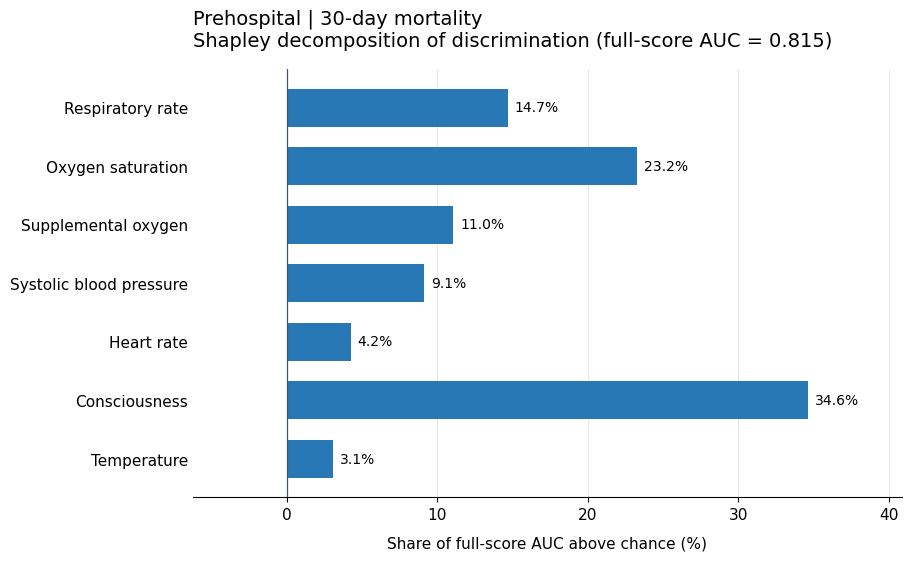

In [ ]:
attribution_m30d_pre, figure_m30d_pre = plot_news2_auc_attribution(
    results_m30d_pre, FEATURES,
    cohort="Prehospital", outcome="M30D",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_m30d_pre)

### Prehospital — UVI

In [6]:
experiments[('Prehospital', 'UVI')] = run_matched_experiment('Prehospital', 'UVI')
results_uvi_pre = experiments[('Prehospital', 'UVI')]["gcs13"]
results_uvi_pre.sort_values("auc", ascending=False).head(10)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,threshold_sd,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp
8,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness|temp,blod_oxy + oxigen + blod_pres + consciousness ...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.712145,"[{""auc"":0.7829089688,""balanced_accuracy"":0.706...",0,1,1,1,0,1,1
33,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|oxigen|consciousness|temp,blod_oxy + oxigen + consciousness + temp,"[""blod_oxy"", ""oxigen"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.421637,0.710146,"[{""auc"":0.7887050252,""balanced_accuracy"":0.727...",0,1,1,0,0,1,1
29,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness,blod_oxy + oxigen + blod_pres + consciousness,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.717022,"[{""auc"":0.7812318174,""balanced_accuracy"":0.733...",0,1,1,1,0,1,0
1,sensitivity_prehospital_uvi_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousn...,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.706044,"[{""auc"":0.7652460402,""balanced_accuracy"":0.687...",1,1,1,1,0,1,1
9,sensitivity_prehospital_uvi_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|consciousness|temp,resp_rate + blod_oxy + oxigen + consciousness ...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""conscious...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.709954,"[{""auc"":0.7691187806,""balanced_accuracy"":0.701...",1,1,1,0,0,1,1
32,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|blod_pres|consciousness|temp,blod_oxy + blod_pres + consciousness + temp,"[""blod_oxy"", ""blod_pres"", ""consciousness"", ""te...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.708345,"[{""auc"":0.778814929,""balanced_accuracy"":0.7067...",0,1,0,1,0,1,1
65,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,"[""blod_oxy"", ""oxigen"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.718351,"[{""auc"":0.7885657806,""balanced_accuracy"":0.745...",0,1,1,0,0,1,0
3,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|heart_rate|conscious...,blod_oxy + oxigen + blod_pres + heart_rate + c...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""heart_rat...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.483046,0.697403,"[{""auc"":0.7827983191,""balanced_accuracy"":0.708...",0,1,1,1,1,1,1
71,sensitivity_prehospital_uvi_gcs13_10fold_seed42,blod_oxy|consciousness|temp,blod_oxy + consciousness + temp,"[""blod_oxy"", ""consciousness"", ""temp""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.709268,"[{""auc"":0.7850647736,""balanced_accuracy"":0.722...",0,1,0,0,0,1,1
11,sensitivity_prehospital_uvi_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousness,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.704563,"[{""auc"":0.7616604918,""balanced_accuracy"":0.690...",1,1,1,1,0,1,0


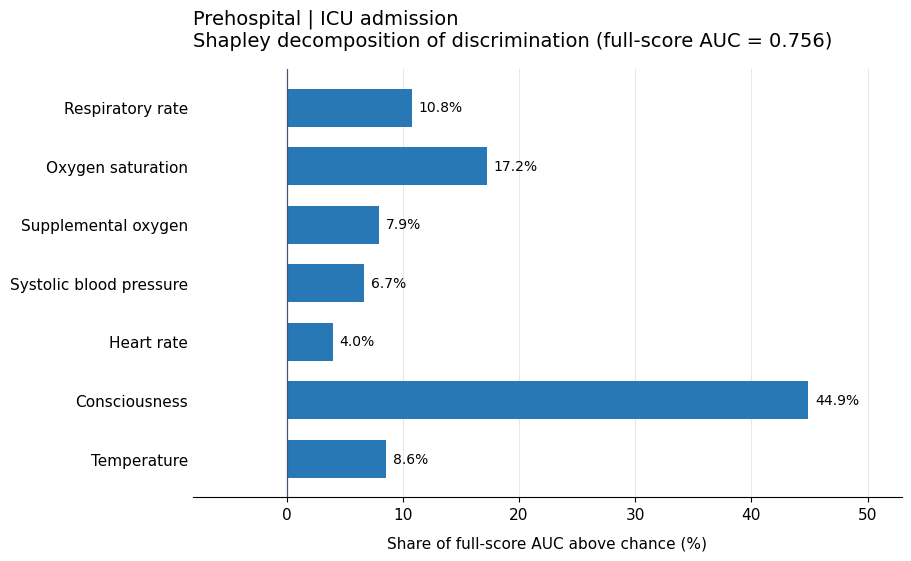

In [7]:
attribution_uvi_pre, figure_uvi_pre = plot_news2_auc_attribution(
    results_uvi_pre, FEATURES,
    cohort="Prehospital", outcome="UVI",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_uvi_pre)

### Hospital — M30D

In [8]:
experiments[('Hospital', 'M30D')] = run_matched_experiment('Hospital', 'M30D')
results_m30d_hosp = experiments[('Hospital', 'M30D')]["gcs13"]
results_m30d_hosp.sort_values("auc", ascending=False).head(10)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,threshold_sd,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp
34,sensitivity_hospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness,blod_oxy + oxigen + blod_pres + consciousness,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.316228,0.794330,"[{""auc"":0.8665445665,""balanced_accuracy"":0.804...",0,1,1,1,0,1,0
8,sensitivity_hospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousness,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.799047,"[{""auc"":0.8594438425,""balanced_accuracy"":0.798...",1,1,1,1,0,1,0
10,sensitivity_hospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|heart_rate|conscious...,blod_oxy + oxigen + blod_pres + heart_rate + c...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""heart_rat...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.795586,"[{""auc"":0.8591704071,""balanced_accuracy"":0.796...",0,1,1,1,1,1,0
33,sensitivity_hospital_m30d_gcs13_10fold_seed42,resp_rate|oxigen|blod_pres|consciousness,resp_rate + oxigen + blod_pres + consciousness,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""consciou...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.843274,0.797150,"[{""auc"":0.8569846429,""balanced_accuracy"":0.793...",1,0,1,1,0,1,0
5,sensitivity_hospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousn...,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.788634,"[{""auc"":0.8642246642,""balanced_accuracy"":0.778...",1,1,1,1,0,1,1
40,sensitivity_hospital_m30d_gcs13_10fold_seed42,oxigen|blod_pres|heart_rate|consciousness,oxigen + blod_pres + heart_rate + consciousness,"[""oxigen"", ""blod_pres"", ""heart_rate"", ""conscio...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.483046,0.788834,"[{""auc"":0.8590534661,""balanced_accuracy"":0.791...",0,0,1,1,1,1,0
16,sensitivity_hospital_m30d_gcs13_10fold_seed42,resp_rate|oxigen|blod_pres|consciousness|temp,resp_rate + oxigen + blod_pres + consciousness...,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""consciou...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.483046,0.791435,"[{""auc"":0.8627371064,""balanced_accuracy"":0.783...",1,0,1,1,0,1,1
4,sensitivity_hospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|blod_pres|heart_rate|conscious...,blod_oxy + oxigen + blod_pres + heart_rate + c...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""heart_rat...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.791053,"[{""auc"":0.8616794786,""balanced_accuracy"":0.778...",0,1,1,1,1,1,1
66,sensitivity_hospital_m30d_gcs13_10fold_seed42,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,"[""blod_oxy"", ""oxigen"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.796254,"[{""auc"":0.8510911624,""balanced_accuracy"":0.770...",0,1,1,0,0,1,0
1,sensitivity_hospital_m30d_gcs13_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.796110,"[{""auc"":0.8521401916,""balanced_accuracy"":0.791...",1,1,1,1,1,1,0


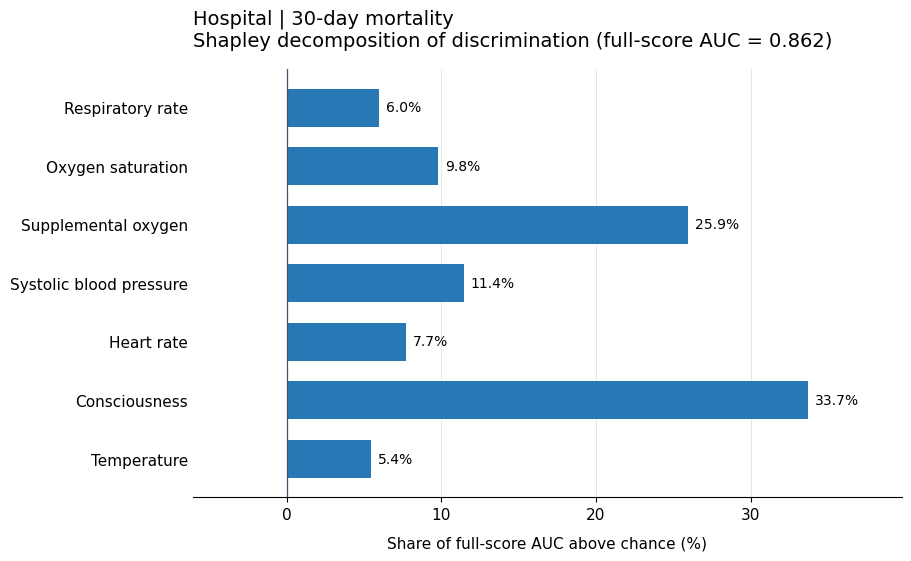

In [9]:
attribution_m30d_hosp, figure_m30d_hosp = plot_news2_auc_attribution(
    results_m30d_hosp, FEATURES,
    cohort="Hospital", outcome="M30D",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_m30d_hosp)

### Hospital — UVI

In [10]:
experiments[('Hospital', 'UVI')] = run_matched_experiment('Hospital', 'UVI')
results_uvi_hosp = experiments[('Hospital', 'UVI')]["gcs13"]
results_uvi_hosp.sort_values("auc", ascending=False).head(10)

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

Completed: 127/127 subsets
Pending: 0 subsets


NEWS2 subsets: 100%|##########| 127/127 [00:00<?, ?it/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,threshold_sd,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp
66,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|heart_rate|consciousness,oxigen + heart_rate + consciousness,"[""oxigen"", ""heart_rate"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.766829,"[{""auc"":0.8440111842,""balanced_accuracy"":0.766...",0,0,1,0,1,1,0
32,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|blod_pres|heart_rate|consciousness,oxigen + blod_pres + heart_rate + consciousness,"[""oxigen"", ""blod_pres"", ""heart_rate"", ""conscio...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.421637,0.770818,"[{""auc"":0.8281834228,""balanced_accuracy"":0.736...",0,0,1,1,1,1,0
64,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|blod_pres|consciousness,oxigen + blod_pres + consciousness,"[""oxigen"", ""blod_pres"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.775002,"[{""auc"":0.825214171,""balanced_accuracy"":0.7462...",0,0,1,1,0,1,0
34,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|heart_rate|consciousness|temp,oxigen + heart_rate + consciousness + temp,"[""oxigen"", ""heart_rate"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.483046,0.768540,"[{""auc"":0.8330084569,""balanced_accuracy"":0.751...",0,0,1,0,1,1,1
31,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|blod_pres|consciousness|temp,oxigen + blod_pres + consciousness + temp,"[""oxigen"", ""blod_pres"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.769489,"[{""auc"":0.8165181124,""balanced_accuracy"":0.740...",0,0,1,1,0,1,1
69,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|consciousness|temp,oxigen + consciousness + temp,"[""oxigen"", ""consciousness"", ""temp""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.764050,"[{""auc"":0.8268005213,""balanced_accuracy"":0.747...",0,0,1,0,0,1,1
8,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|blod_pres|heart_rate|consciousness|temp,oxigen + blod_pres + heart_rate + consciousnes...,"[""oxigen"", ""blod_pres"", ""heart_rate"", ""conscio...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.770689,"[{""auc"":0.8201925615,""balanced_accuracy"":0.738...",0,0,1,1,1,1,1
99,sensitivity_hospital_uvi_gcs13_10fold_seed42,oxigen|consciousness,oxigen + consciousness,"[""oxigen"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.773944,"[{""auc"":0.8336806625,""balanced_accuracy"":0.783...",0,0,1,0,0,1,0
33,sensitivity_hospital_uvi_gcs13_10fold_seed42,resp_rate|oxigen|consciousness|temp,resp_rate + oxigen + consciousness + temp,"[""resp_rate"", ""oxigen"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.768410,"[{""auc"":0.8215067303,""balanced_accuracy"":0.763...",1,0,1,0,0,1,1
9,sensitivity_hospital_uvi_gcs13_10fold_seed42,resp_rate|oxigen|blod_pres|consciousness|temp,resp_rate + oxigen + blod_pres + consciousness...,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""consciou...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.000000,0.770152,"[{""auc"":0.8096503431,""balanced_accuracy"":0.756...",1,0,1,1,0,1,1


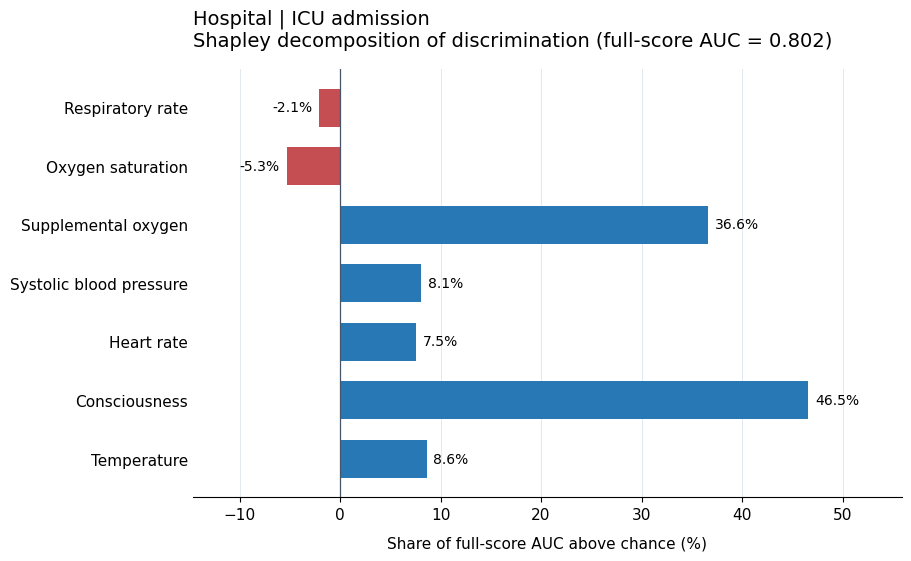

In [11]:
attribution_uvi_hosp, figure_uvi_hosp = plot_news2_auc_attribution(
    results_uvi_hosp, FEATURES,
    cohort="Hospital", outcome="UVI",
    output_dir=OUTPUT_DIR / "shapley_auc",
)
plt.show()
plt.close(figure_uvi_hosp)

## 4. Compare all matched subsets

Differences are modified minus baseline. Positive values favor the modified score. Subsets without consciousness must remain unchanged because scores, patients, and folds are identical.

In [12]:
comparisons = []
for (setting, outcome), variants in experiments.items():
    metrics = ["subset_key", "subset_label", "n_features", "auc", "balanced_accuracy"]
    paired = variants["baseline"][metrics].merge(
        variants["gcs13"][["subset_key", "auc", "balanced_accuracy"]],
        on="subset_key", suffixes=("_baseline", "_gcs13"), validate="one_to_one",
    )
    paired["cohort"] = setting
    paired["outcome"] = outcome
    paired["delta_auc"] = paired["auc_gcs13"] - paired["auc_baseline"]
    paired["delta_ba"] = paired["balanced_accuracy_gcs13"] - paired["balanced_accuracy_baseline"]
    no_consciousness = ~paired["subset_key"].str.split("|").map(lambda names: "consciousness" in names)
    if not np.allclose(paired.loc[no_consciousness, ["delta_auc", "delta_ba"]], 0, atol=1e-12):
        raise ValueError("Subsets without consciousness changed: inspect patient/fold alignment.")
    comparisons.append(paired)
comparison = pd.concat(comparisons, ignore_index=True)
comparison.to_csv(OUTPUT_DIR / "gcs13_vs_baseline_all_subsets.csv", index=False)
comparison.loc[comparison["n_features"].eq(7)]

,subset_key,subset_label,n_features,auc_baseline,balanced_accuracy_baseline,auc_gcs13,balanced_accuracy_gcs13,cohort,outcome,delta_auc,delta_ba
0,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.814682,0.734846,0.814840,0.740599,Prehospital,M30D,0.000158,0.005754
127,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.758032,0.695546,0.756129,0.691916,Prehospital,UVI,-0.001903,-0.003630
254,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.861442,0.783903,0.862271,0.780209,Hospital,M30D,0.000829,-0.003694
381,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.801236,0.752258,0.802485,0.754020,Hospital,UVI,0.001249,0.001762


In [13]:
comparison.loc[comparison["subset_key"].eq("blod_oxy|oxigen|consciousness")]

,subset_key,subset_label,n_features,auc_baseline,balanced_accuracy_baseline,auc_gcs13,balanced_accuracy_gcs13,cohort,outcome,delta_auc,delta_ba
64,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,3,0.821069,0.758616,0.822277,0.768247,Prehospital,M30D,0.001208,0.009631
192,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,3,0.764245,0.718469,0.761909,0.718351,Prehospital,UVI,-0.002336,-0.000117
320,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,3,0.862776,0.792019,0.862573,0.796254,Hospital,M30D,-0.000204,0.004235
452,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,3,0.810051,0.757773,0.810543,0.747058,Hospital,UVI,0.000492,-0.010715


## 5. AUC changes by subset size: subsets containing consciousness

Each point represents one matched parameter subset containing consciousness. Its change is **AUC with GCS < 13 minus baseline AUC** on the same patients and folds. Positive values favor the modified threshold; negative values favor the baseline.

The 64 subsets are grouped by the number of retained parameters: **1, 6, 15, 20, 15, 6, and 1 subsets** at sizes 1–7. Sizes 1 and 7 show a single point. Sizes 2–6 show a box (median and interquartile range), whiskers extending to the most extreme observations within 1.5 interquartile ranges, and every individual observation. Horizontal offsets separate overlapping points and have no analytical meaning.

These distributions describe variation across parameter combinations, **not bootstrap confidence intervals**. All four plots use the same vertical range and Turbo colors for subset sizes. Balanced-accuracy differences remain available in the comparison CSV.

### Prehospital — 30-day mortality

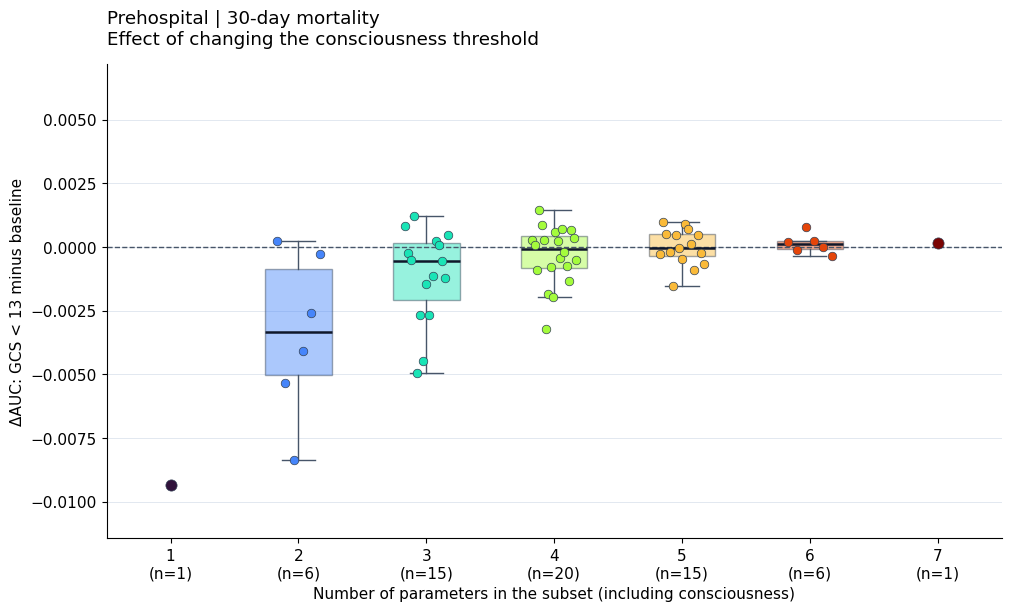

In [14]:
figure = plot_gcs_delta_auc_by_size(
    comparison, setting='Prehospital', outcome='M30D',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

### Prehospital — ICU admission

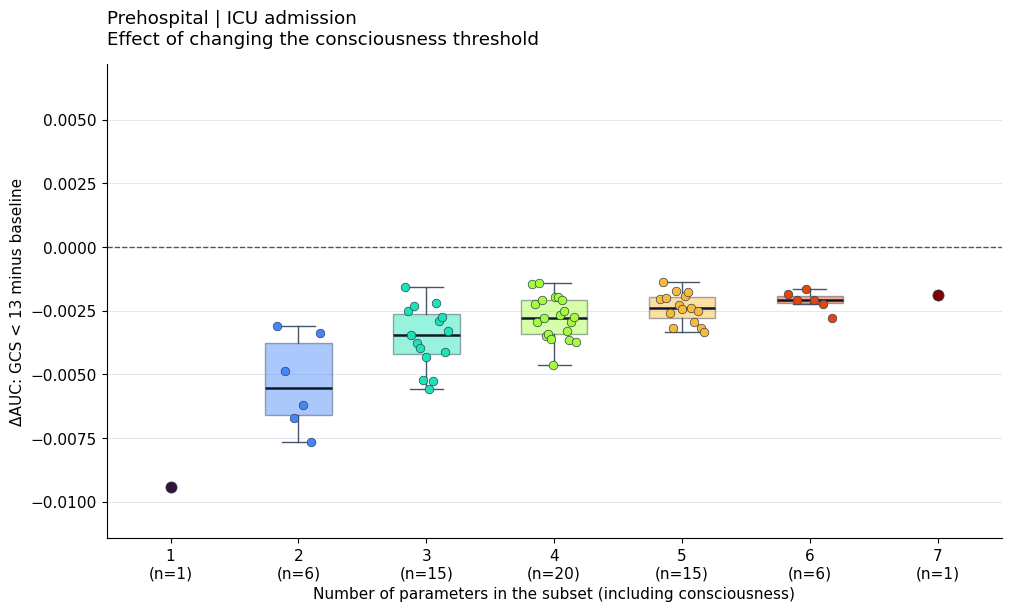

In [15]:
figure = plot_gcs_delta_auc_by_size(
    comparison, setting='Prehospital', outcome='UVI',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

### Hospital — 30-day mortality

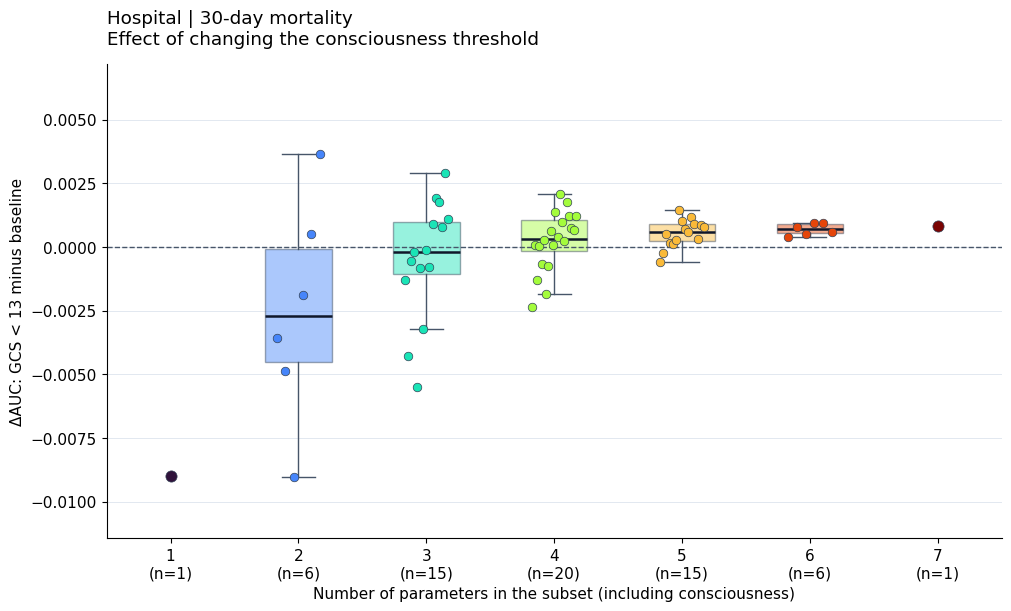

In [16]:
figure = plot_gcs_delta_auc_by_size(
    comparison, setting='Hospital', outcome='M30D',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

### Hospital — ICU admission

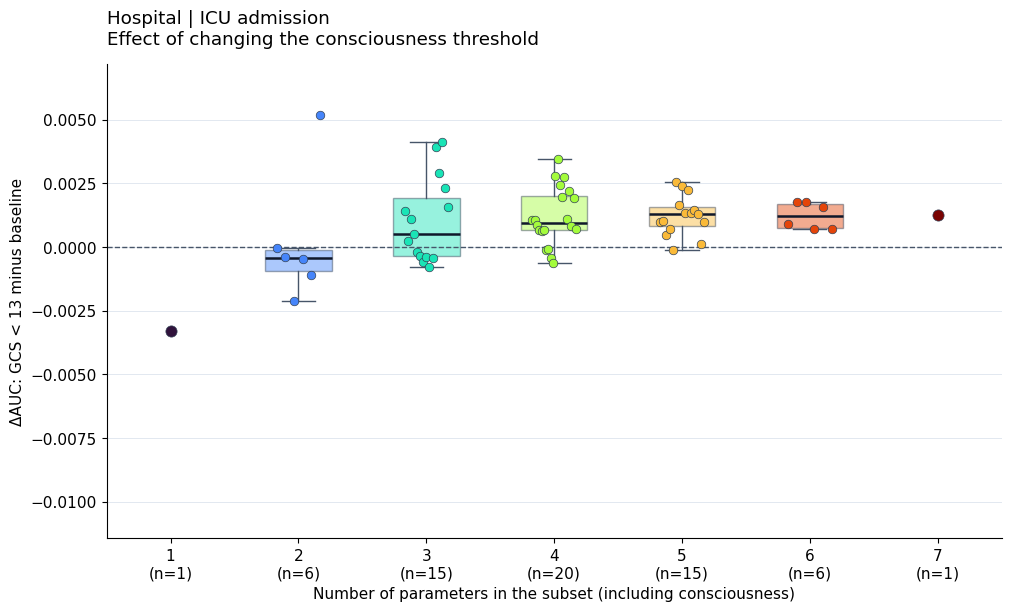

In [17]:
figure = plot_gcs_delta_auc_by_size(
    comparison, setting='Hospital', outcome='UVI',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

## Interpretation

The modified score removes three consciousness points from patients with GCS 13–14. Compare the full-score and subset AUC/BA differences, and inspect whether Shapley attribution and pairwise dominance change. These differences are descriptive; this notebook does not calculate confidence intervals or significance tests. Do not interpret this sensitivity score as a validated clinical replacement for NEWS2.